In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os

In [1]:
def foce_analysis(dataset_file):
    # Read the dataset file
    with open(dataset_file, 'r') as file:
        lines = file.readlines()
   

    energies=[]
    n_atom_per_structure=[]
    mean_module_square=[]
    atom_count=0
    struct_count=0
    tmp=0
    for i , line in enumerate(lines):
        
        if line.startswith('atom'):
            split_line=line.split()
            #print(split_line)
            tmp=tmp+  float(split_line[7])**2+ float(split_line[8])**2+ float(split_line[9])**2
            
            #print(tmp)
            atom_count=atom_count+1
          
        if line.startswith('energy'): 
            split_line=line.split()
            #print(split_line[1])
            energies.append(float(split_line[1]))
            mean_module_square.append(tmp/atom_count)
            n_atom_per_structure.append(atom_count)
            struct_count=struct_count+1
            
            atom_count=0 
            tmp=0
    print(struct_count)
            
       
            
        
    
    return energies, mean_module_square, n_atom_per_structure

In [3]:
folder_path = "./"

# Get a list of all files in the folder
all_files = os.listdir(folder_path)

# Filter files with the .data extension
data_files = [file for file in all_files if file.endswith(".data")]
data_files.sort()
# Loop over the .data files
for data in data_files:
    print(data)

input_114.data
input_126.data
input_132.data
input_138.data
input_144.data
input_150.data
input_156.data
input_162.data
input_186.data
input_210.data
input_234.data
input_384.data


In [4]:
energies=[0]*len(data_files)
mean_force=[0]*len(data_files)
n_atom=[0]*len(data_files)


for i, data in enumerate(data_files):
    energies[i], mean_force[i], n_atom[i]=foce_analysis(data)




1483
1229
1897
2448
3272
2516
3063
1007
736
856
2497
1263


In [6]:

sort_energies=[]
sort_indices=[]
for i, data in enumerate(data_files):
    sort_energies.append(np.sort(energies[i]))
    sort_indices.append(np.argsort(energies[i]))

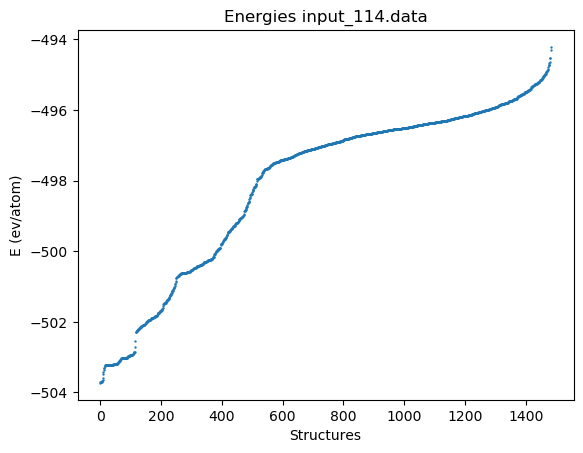

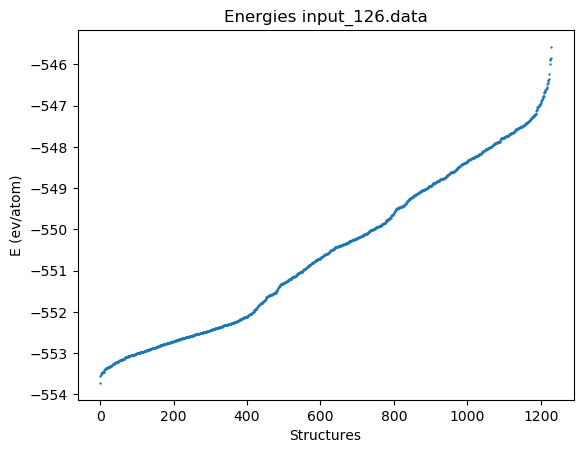

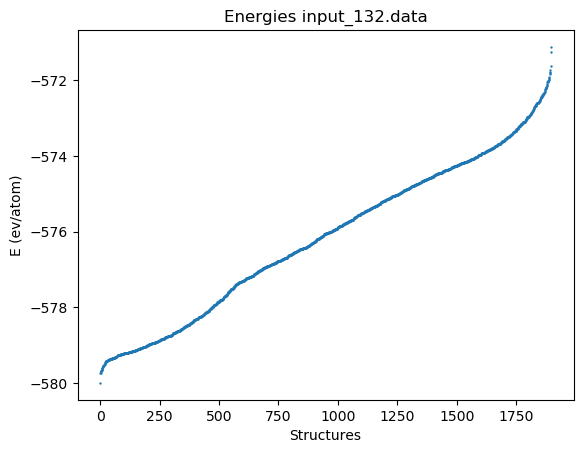

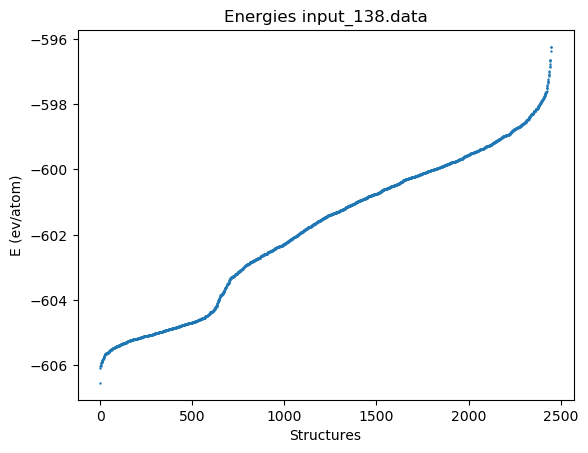

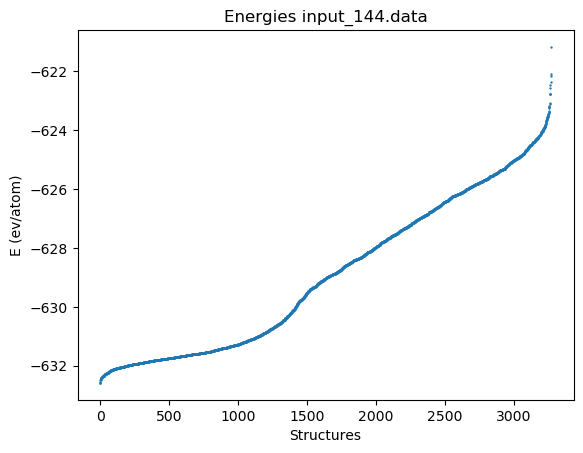

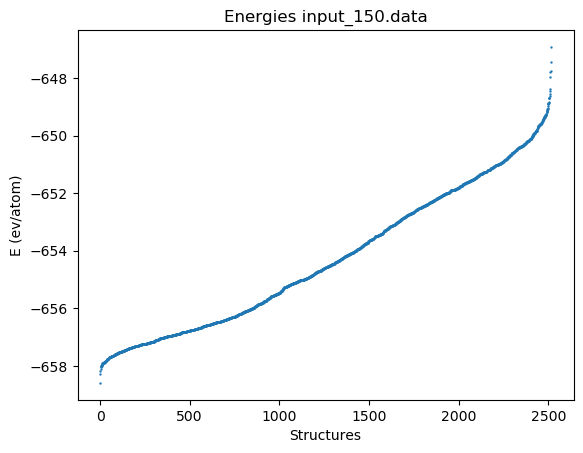

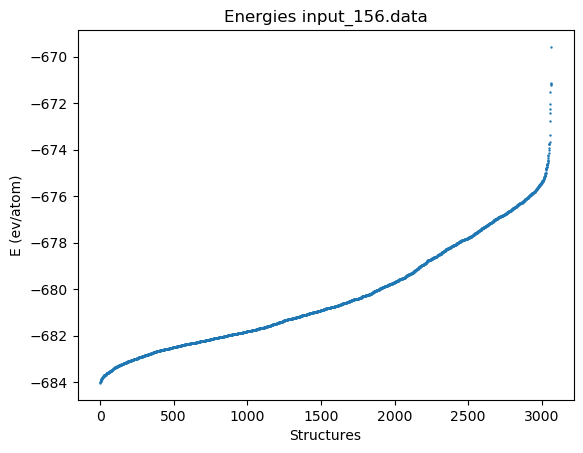

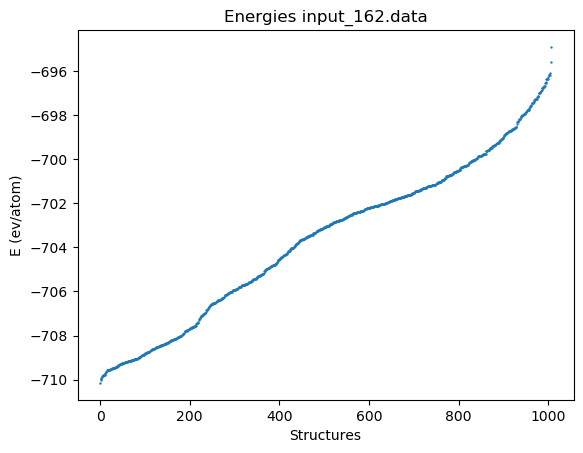

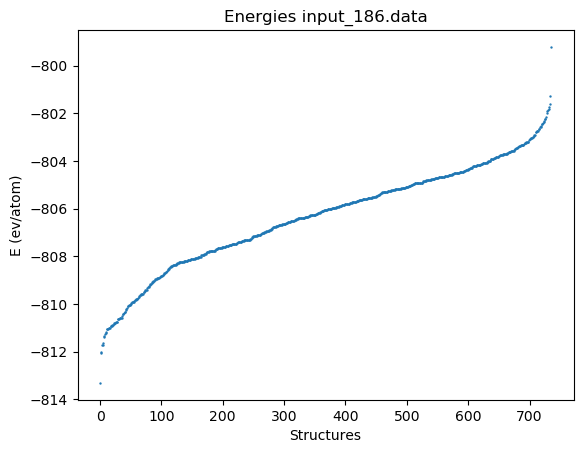

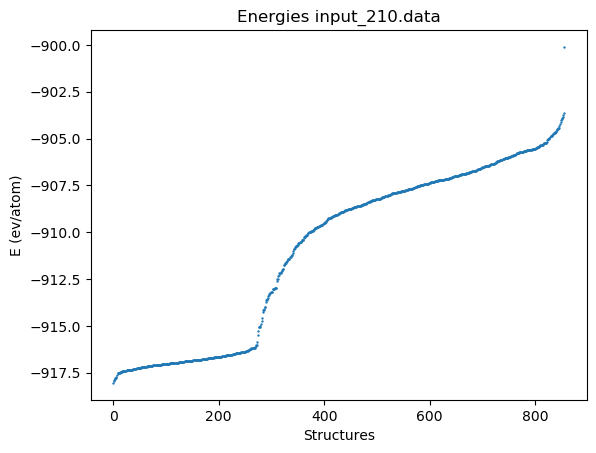

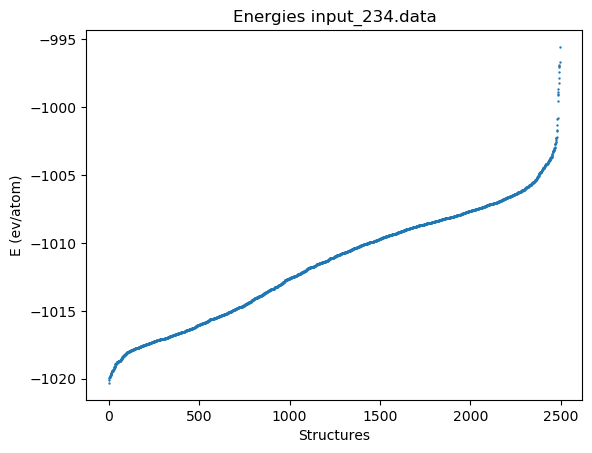

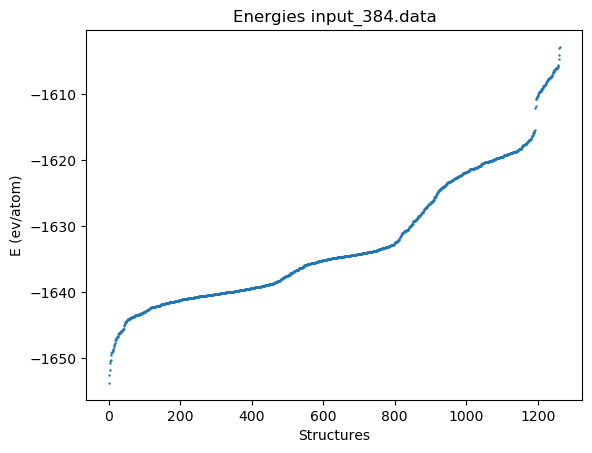

In [16]:
for i, data in enumerate(data_files):
    plt.figure(i+1)
    plt.scatter(np.arange(len(energies[i])),sort_energies[i], s = 0.5)
    plt.xlabel("Structures")
    plt.ylabel("E (ev/atom)")
    plt.title('Energies {}'.format(data))
    plt.savefig('/data/home/salvatorer26/Desktop/group_meeting/pres_6/{}.png'.format(data.replace(".data", "")))

In [10]:
def print_configurations(dataset_file, structures, good_input_data, control):
    # Read the dataset file
    with open(dataset_file, 'r') as file:
        lines = file.readlines()
    struct_count=0
    not_count=0   
    #print(index)
    with open(good_input_data, 'w') as new_file:
        index=0
        
        for i, line in enumerate(lines):
            if line.startswith('begin'): 
                if index in structures:
                    if control:
                        bool=True
                    else:
                        bool=False
                    struct_count+=1
                else: 
                    if control:
                        bool=False
                    else:
                        bool=True
                    not_count += 1
                index += 1
            if bool:
                new_file.write(line)
    print("old lenght:", index)    
    print(" str lenght:",struct_count )       
    if control:
        print("new lenght:",struct_count) 
    else:
        print("new lenght:",not_count) 
        
    
    return 

In [53]:
def find_offset_lines(dataset_file):
    with open(dataset_file, 'r') as file:
        lines = file.readlines()
    struct_count=0
     
    offset_lines=[]
    for i, line in enumerate(lines):
        if line.startswith('begin'): 
                    struct_count+=1
                    offset_lines.append(i+1)

    return offset_lines  


def print_reordered_configurations(dataset_file, sort_indices, ordered_input_data ):
    
    offset_lines=find_offset_lines(dataset_file)
    
    ordered_offset=[offset_lines[k] for k in sort_indices ]
    print(ordered_offset)
    
    with open(ordered_input_data, 'w') as new_file:
   
        for starting_line in ordered_offset:
            print(starting_line)

            # Move to the desired starting line

            with open(dataset_file, 'r') as file:
            # Read lines until the target pattern is found
            
                for _ in range(starting_line-1):
                    file.readline()
                    
                for current_line in file: 
                    #print(current_line)
                        
                    new_file.write(current_line)
                    if "end" in current_line:
                        print("finished with {}".format(starting_line))
                        break  # Stop reading when the target pattern is found

        
    
    return 

In [55]:
for i, data in enumerate(data_files):
    start_file=data      #starting input.data
    input_sort_indices=sort_indices[i]            #sorted indices
    ordered_file="ordered_{}".format(data)

    print_reordered_configurations(start_file, input_sort_indices, ordered_file)

[180683, 180073, 180195, 180805, 180317, 180561, 180439, 179951, 179829, 179707, 179585, 179463, 179341, 179219, 179097, 178975, 140545, 138227, 140301, 140423, 138349, 138105, 140667, 137983, 140179, 140911, 140789, 138471, 137861, 138593, 178853, 139813, 141155, 141033, 139935, 140057, 141643, 141277, 137617, 139691, 141521, 137739, 137495, 141765, 138715, 139569, 137373, 141399, 137251, 139447, 137129, 138837, 138959, 139325, 139203, 137007, 139081, 178731, 136885, 136763, 136641, 136519, 136397, 136275, 136153, 136031, 135909, 178609, 135787, 135665, 135543, 135421, 135177, 135055, 135299, 133835, 133591, 133957, 133713, 133469, 134933, 134079, 134689, 134811, 134567, 134445, 134201, 134323, 133347, 133225, 133103, 132981, 132859, 132737, 132615, 132493, 132371, 132249, 132127, 132005, 131395, 131883, 131517, 131273, 131639, 131151, 131761, 131029, 130907, 130785, 130663, 130541, 130419, 178487, 130297, 178365, 178243, 130175, 178121, 130053, 129931, 129809, 129687, 129565, 129443,

In [31]:
test_file="input_114.data"           #name of the input.data to be cleaned
offset_lines=find_offset_lines(test_file)

In [32]:
ordered_offset=[offset_lines[k] for k in sort_indices[0] ]

In [35]:
#offset_lines
ordered_offset


[180683,
 180073,
 180195,
 180805,
 180317,
 180561,
 180439,
 179951,
 179829,
 179707,
 179585,
 179463,
 179341,
 179219,
 179097,
 178975,
 140545,
 138227,
 140301,
 140423,
 138349,
 138105,
 140667,
 137983,
 140179,
 140911,
 140789,
 138471,
 137861,
 138593,
 178853,
 139813,
 141155,
 141033,
 139935,
 140057,
 141643,
 141277,
 137617,
 139691,
 141521,
 137739,
 137495,
 141765,
 138715,
 139569,
 137373,
 141399,
 137251,
 139447,
 137129,
 138837,
 138959,
 139325,
 139203,
 137007,
 139081,
 178731,
 136885,
 136763,
 136641,
 136519,
 136397,
 136275,
 136153,
 136031,
 135909,
 178609,
 135787,
 135665,
 135543,
 135421,
 135177,
 135055,
 135299,
 133835,
 133591,
 133957,
 133713,
 133469,
 134933,
 134079,
 134689,
 134811,
 134567,
 134445,
 134201,
 134323,
 133347,
 133225,
 133103,
 132981,
 132859,
 132737,
 132615,
 132493,
 132371,
 132249,
 132127,
 132005,
 131395,
 131883,
 131517,
 131273,
 131639,
 131151,
 131761,
 131029,
 130907,
 130785,
 130663,
 

In [150]:
for i , n in enumerate(list_atom_number):
    structure_list=   n_ordered_input_index[i] #list of structure indices (containing zero structure) or if file.txt np.loadtxt("name of file txt")
    new_input_data="input_{}.data".format(n)                            #name of the output file 
    control= True   #set True to print the structures in structure_list, False to print all except from those
    print_configurations(dataset_file, structure_list, new_input_data, control)

old lenght: 22267
 str lenght: 1483
new lenght: 1483
old lenght: 22267
 str lenght: 1229
new lenght: 1229
old lenght: 22267
 str lenght: 1897
new lenght: 1897
old lenght: 22267
 str lenght: 2448
new lenght: 2448
old lenght: 22267
 str lenght: 3272
new lenght: 3272
old lenght: 22267
 str lenght: 2516
new lenght: 2516
old lenght: 22267
 str lenght: 3063
new lenght: 3063
old lenght: 22267
 str lenght: 1007
new lenght: 1007
old lenght: 22267
 str lenght: 736
new lenght: 736
old lenght: 22267
 str lenght: 856
new lenght: 856
old lenght: 22267
 str lenght: 2497
new lenght: 2497
old lenght: 22267
 str lenght: 1263
new lenght: 1263
